# WattRota — Elektrik Fiyatlarının Keşifsel Analizi

**Hazırlayan:** Rana Beyza Culus

Bu notebook, saatlik elektrik fiyatlarının zaman içindeki değişimini ve üretim çizelgelemesinde değerlendirilebilecek fiyat farklarını inceler. Bu dosya veri hazırlama, kalite kontrolleri ve keşifsel analiz sonuçlarını içerir.

## 1. Veri kaynağı ve kapsam

Kaynak: [EPİAŞ Şeffaflık Platformu](https://seffaflik.epias.com.tr/), Elektrik Piyasaları → Gün Öncesi Piyasası → Piyasa Takas Fiyatı.

| Dosya dönemi | Beklenen kayıt |
|---|---:|
| 1 Ocak–31 Aralık 2024 | 8.784 |
| 1 Ocak–31 Aralık 2025 | 8.760 |
| 1 Ocak–6 Kasım 2026 | 7.440 |

CSV dosyaları 7 Kasım 2026'da indirilmiş sabit veri kopyalarıdır; bu notebook otomatik veri güncellemesi yapmaz. Ham dosyalar değiştirilmez. Zamanlar Türkiye yerel saati olarak yorumlanır; tarih-saat sütunu saat dilimi etiketi içermez.

| Sütun | Açıklama |
|---|---|
| Tarih, Saat | Fiyatın ait olduğu gün ve saatlik dönemin başlangıcı |
| PTF (TL/MWh) | Saatlik piyasa takas fiyatı; ana analiz değişkeni |
| PTF (USD/MWh), PTF (EUR/MWh) | Kaynakta sunulan döviz cinsinden fiyatlar |
| tarih_saat | Tarih ve saatten oluşturulan zaman bilgisi |

PTF, işletmenin vergiler ve diğer bedeller dâhil nihai elektrik maliyeti değildir. Yıllar arası TL karşılaştırmaları nominaldir; enflasyondan arındırılmamıştır.


In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Notebook, proje kökünden veya notebooks klasöründen çalıştırılabilir.
proje_dizini = Path.cwd()
if not (proje_dizini / "data" / "raw" / "epias").is_dir():
    proje_dizini = proje_dizini.parent
veri_dizini = proje_dizini / "data" / "raw" / "epias"
if not veri_dizini.is_dir():
    raise FileNotFoundError("Projenin data/raw/epias klasörü bulunamadı.")

print("pandas:", pd.__version__)
print("Veri klasörü:", veri_dizini)


pandas: 3.1.1
Veri klasörü: C:\Users\Victus\Documents\ChatGPT\WattRota\data\raw\epias


## 2. Dosyaların okunması ve veri kalitesi

CSV'lerde sütun ayracı `;`, ondalık ayracı `,`, binlik ayracı `.`. Tarih sütununu metin olarak okuyarak tarihlerdeki noktaların sayı ayracı sayılmasını önlüyoruz. Her dosya, kendi beklenen tarih aralığına göre kontrol edilir.


In [2]:
dosyalar = {
    2024: ("Piyasa_Takas_Fiyati-01012024-31122024.csv", "2024-12-31 23:00"),
    2025: ("Piyasa_Takas_Fiyati-01012025-31122025.csv", "2025-12-31 23:00"),
    2026: ("Piyasa_Takas_Fiyati-01012026-06112026.csv", "2026-11-06 23:00"),
}
fiyat_sutunlari = ["PTF (TL/MWh)", "PTF (USD/MWh)", "PTF (EUR/MWh)"]
tablolar = {}
kontroller = []

for yil, (dosya_adi, bitis) in dosyalar.items():
    tablo = pd.read_csv(
        veri_dizini / dosya_adi,
        sep=";", dtype={"Tarih": str, "Saat": str},
        decimal=",", thousands=".",
    )
    tablo["tarih_saat"] = pd.to_datetime(
        tablo["Tarih"] + " " + tablo["Saat"],
        format="%d.%m.%Y %H:%M", errors="raise",
    )
    beklenen = pd.date_range(f"{yil}-01-01", bitis, freq="h")
    mevcut_saatler = pd.DatetimeIndex(tablo["tarih_saat"])
    kontrol = {
        "yil": yil,
        "kayit": len(tablo),
        "beklenen": len(beklenen),
        "ilk_zaman": mevcut_saatler.min(),
        "son_zaman": mevcut_saatler.max(),
        "eksik_saat": len(beklenen.difference(mevcut_saatler)),
        "donem_disi_saat": len(mevcut_saatler.difference(beklenen)),
        "tekrar": int(mevcut_saatler.duplicated().sum()),
        "eksik_fiyat": int(tablo[fiyat_sutunlari].isna().sum().sum()),
    }
    kontroller.append(kontrol)
    if any(kontrol[alan] for alan in ["eksik_saat", "donem_disi_saat", "tekrar", "eksik_fiyat"]):
        raise ValueError(f"{yil} dosyasında veri kalitesi sorunu var: {kontrol}")
    if not all(pd.api.types.is_numeric_dtype(tablo[s]) for s in fiyat_sutunlari):
        raise TypeError(f"{yil} dosyasında fiyat sütunları sayısal okunamadı.")
    tablolar[yil] = tablo

kalite_ozeti = pd.DataFrame(kontroller).set_index("yil")
kalite_ozeti


Out[2]: 
      kayit  beklenen  ilk_zaman  ...  donem_disi_saat  tekrar  eksik_fiyat
yil                               ...                                      
2024   8784      8784 2024-01-01  ...                0       0            0
2025   8760      8760 2025-01-01  ...                0       0            0
2026   7440      7440 2026-01-01  ...                0       0            0

[3 rows x 8 columns]


In [3]:
df_2024, df_2025, df_2026 = (tablolar[yil] for yil in [2024, 2025, 2026])
df = pd.concat(tablolar.values(), ignore_index=True)
df = df.sort_values("tarih_saat").reset_index(drop=True)

beklenen_tum_saatler = pd.date_range("2024-01-01", "2026-11-06 23:00", freq="h")
if df["tarih_saat"].duplicated().any() or not pd.DatetimeIndex(df["tarih_saat"]).equals(beklenen_tum_saatler):
    raise ValueError("Birleşik zaman dizisi beklenen saatlerle eşleşmiyor.")

df["yil"] = df["tarih_saat"].dt.year
df["ay"] = df["tarih_saat"].dt.month
df["saat"] = df["tarih_saat"].dt.hour
df["haftanin_gunu"] = df["tarih_saat"].dt.day_of_week
df["hafta_sonu"] = df["haftanin_gunu"] >= 5

print(f"Toplam {len(df):,} kayıt; eksik veya tekrarlanan saat yok.")
df.head()


Toplam 24,984 kayıt; eksik veya tekrarlanan saat yok.
Out[3]: 
        Tarih   Saat  PTF (TL/MWh)  ...  saat  haftanin_gunu  hafta_sonu
0  01.01.2024  00:00       1299.98  ...     0              0       False
1  01.01.2024  01:00       1299.98  ...     1              0       False
2  01.01.2024  02:00       1248.54  ...     2              0       False
3  01.01.2024  03:00       1299.98  ...     3              0       False
4  01.01.2024  04:00       1200.00  ...     4              0       False

[5 rows x 11 columns]


## 3. Fiyat seviyeleri ve sıfır fiyatlar

Aşağıdaki özetler her dosyanın kendi kapsamını gösterir; 2026 tam yıl değildir. Sıfır PTF kayıtları veri hatası kabul edilerek silinmez.


In [4]:
donem_ozeti = df.groupby("yil")["PTF (TL/MWh)"].describe()
sifir_sayilari = df["PTF (TL/MWh)"].eq(0).groupby(df["yil"]).sum()
donem_ozeti["sifir_saat"] = sifir_sayilari
donem_ozeti["sifir_orani_pct"] = sifir_sayilari / donem_ozeti["count"] * 100
donem_ozeti.round(2)


Out[4]: 
       count     mean      std  ...     max  sifir_saat  sifir_orani_pct
yil                             ...                                     
2024  8784.0  2235.52   654.29  ...  3000.0           4             0.05
2025  8760.0  2619.81   801.20  ...  3400.0          42             0.48
2026  7440.0  2086.93  1352.66  ...  4500.0         413             5.55

[3 rows x 10 columns]


## 4. Zaman örüntüleri

### 4.1. 2024: yıl geneli ve örnek hafta

Yıllık grafik genel değişimi, ilk hafta grafiği ise saatlik hareketi gösterir. Tek haftalık örnek bütün yılı temsil etmez.


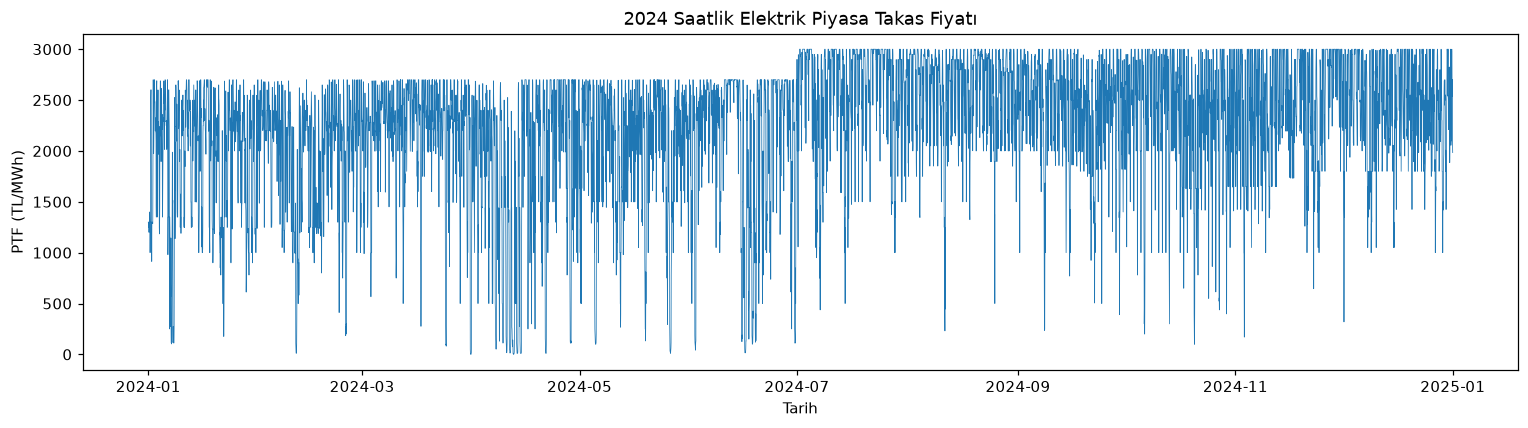

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 4))
plt.plot(df_2024["tarih_saat"], df_2024["PTF (TL/MWh)"], linewidth=0.5)

plt.title("2024 Saatlik Elektrik Piyasa Takas Fiyatı")
plt.xlabel("Tarih")
plt.ylabel("PTF (TL/MWh)")
plt.tight_layout()
plt.show()

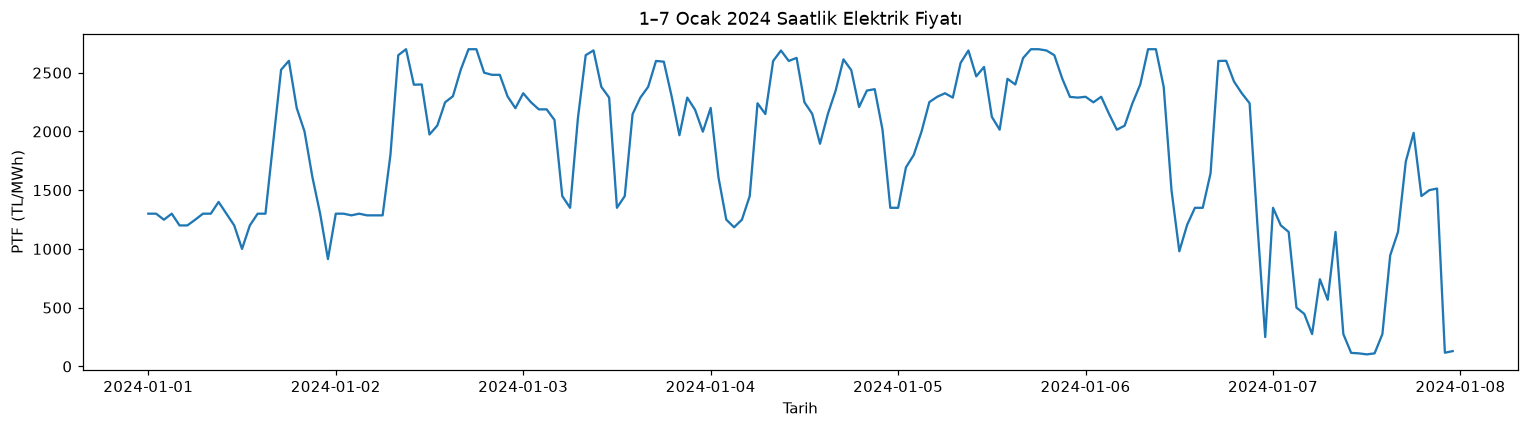

In [6]:
ilk_hafta = df_2024[
    (df_2024["tarih_saat"] >= "2024-01-01")
    & (df_2024["tarih_saat"] < "2024-01-08")
]

plt.figure(figsize=(14, 4))
plt.plot(ilk_hafta["tarih_saat"], ilk_hafta["PTF (TL/MWh)"])

plt.title("1–7 Ocak 2024 Saatlik Elektrik Fiyatı")
plt.xlabel("Tarih")
plt.ylabel("PTF (TL/MWh)")
plt.tight_layout()
plt.show()

### 4.2. Günün saati ve ay

2024 ve 2025 tam yıl üzerinden karşılaştırılır. Saatlik ortalamalar her gün aynı saatlerin ucuz olacağını garanti etmez.


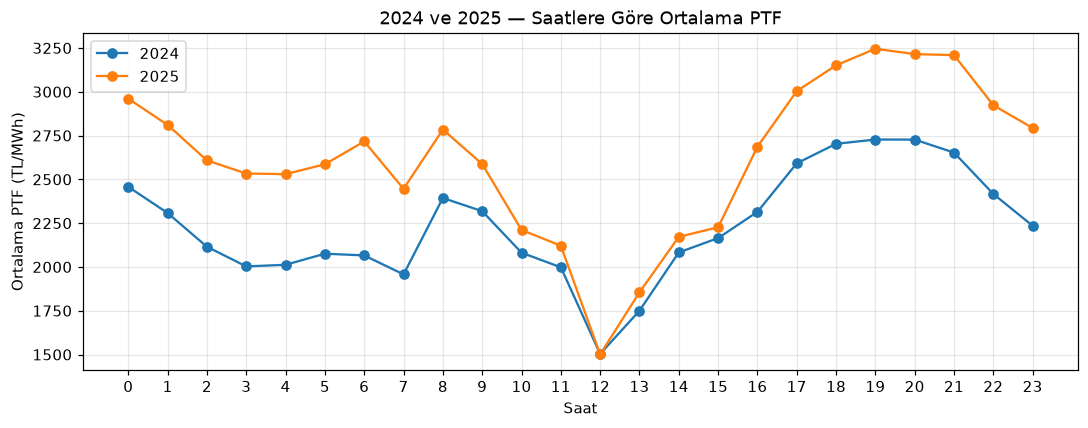

In [7]:
saatlik_ortalama = df_2024.groupby(df_2024["tarih_saat"].dt.hour)["PTF (TL/MWh)"].mean()
saatlik_ortalama_2025 = df_2025.groupby(df_2025["tarih_saat"].dt.hour)["PTF (TL/MWh)"].mean()

pd.DataFrame({"2024": saatlik_ortalama, "2025": saatlik_ortalama_2025}).plot(
    figsize=(10, 4), marker="o"
)
plt.xticks(range(24))
plt.title("2024 ve 2025 — Saatlere Göre Ortalama PTF")
plt.xlabel("Saat")
plt.ylabel("Ortalama PTF (TL/MWh)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [8]:
ay_saat_ortalama = df_2024.groupby([
    df_2024["tarih_saat"].dt.month,
    df_2024["tarih_saat"].dt.hour
])["PTF (TL/MWh)"].mean().unstack()

ay_saat_ortalama.round(2)

Out[8]: 
tarih_saat       0        1        2   ...       21       22       23
tarih_saat                             ...                           
1           1744.65  1622.97  1484.42  ...  2233.91  1888.27  1626.58
2           2015.20  1925.57  1762.36  ...  2240.49  2048.10  1830.79
3           2339.66  2242.21  2182.07  ...  2540.73  2304.54  2229.98
4           2327.30  2094.03  1755.72  ...  2530.49  2199.07  2003.83
5           2404.76  2312.08  2102.12  ...  2634.04  2354.00  2087.13
6           2606.76  2463.91  2333.86  ...  2668.60  2525.86  2392.47
7           2914.30  2783.63  2613.41  ...  2988.86  2884.15  2787.68
8           2879.90  2747.10  2557.28  ...  2972.41  2908.86  2737.49
9           2696.73  2542.24  2343.63  ...  2789.01  2548.87  2356.58
10          2580.59  2450.78  2215.80  ...  2734.89  2511.81  2320.97
11          2490.49  2272.76  2049.64  ...  2785.97  2483.73  2248.41
12          2468.06  2215.79  1959.57  ...  2691.48  2317.88  2169.98

[12 rows x

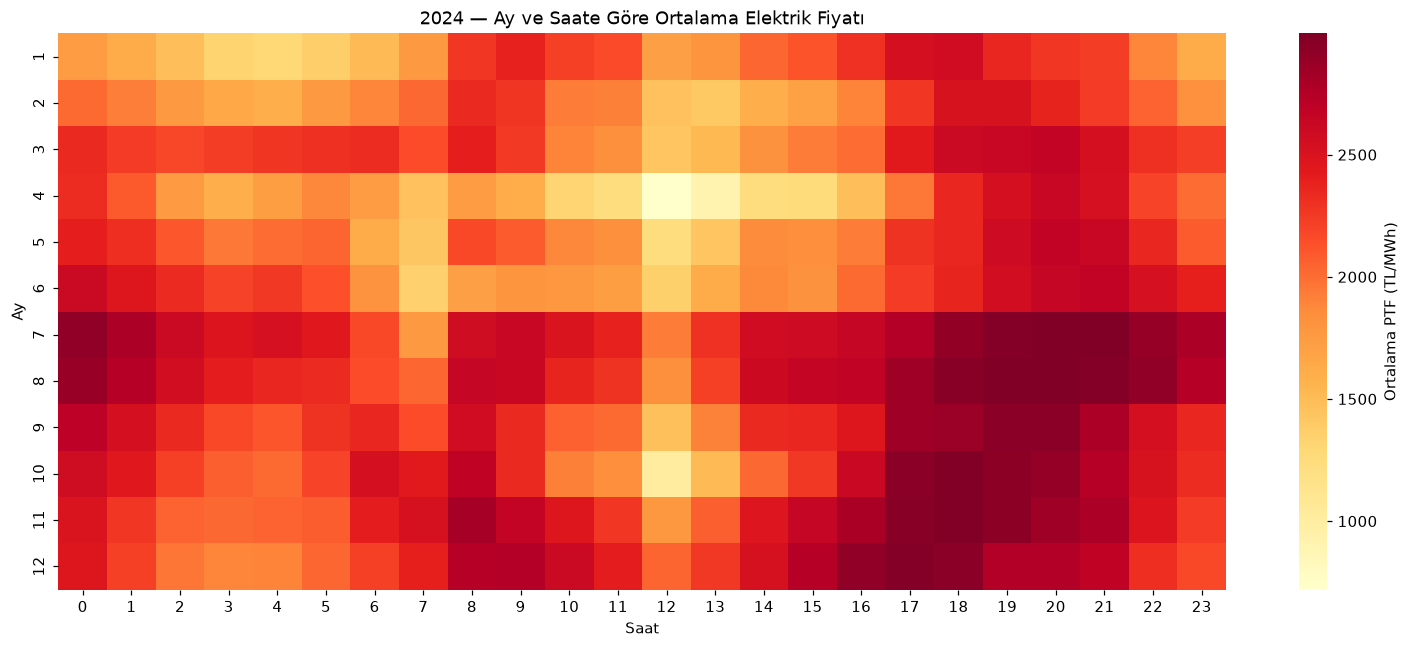

In [9]:
import seaborn as sns

plt.figure(figsize=(14, 6))
sns.heatmap(
    ay_saat_ortalama,
    cmap="YlOrRd",
    cbar_kws={"label": "Ortalama PTF (TL/MWh)"}
)

plt.title("2024 — Ay ve Saate Göre Ortalama Elektrik Fiyatı")
plt.xlabel("Saat")
plt.ylabel("Ay")
plt.tight_layout()
plt.show()

İki yılda da yıllık ortalamada en düşük fiyat 12.00'de, en yüksek fiyat 19.00'da. 2024 ay-saat haritası, fiyat seviyesinin ve saatlik örüntünün aylara göre değiştiğini gösteriyor.


### 4.3. Hafta içi ve hafta sonu — 2025

Bu karşılaştırmada yalnızca 2025 kullanılır; böylece farklı yılların fiyat seviyeleri karışmaz. Hafta sonu cumartesi ve pazardır; resmî tatiller ayrıca sınıflandırılmamıştır.


In [10]:
df["hafta_sonu"] = df["haftanin_gunu"] >= 5

hafta_ici_sonu_2025 = df[df["yil"] == 2025].groupby(
    ["saat", "hafta_sonu"]
)["PTF (TL/MWh)"].mean().unstack()

hafta_ici_sonu_2025.columns = ["Hafta içi", "Hafta sonu"]

hafta_ici_sonu_2025.round(2)

Out[10]: 
      Hafta içi  Hafta sonu
saat                       
0       2957.79     2967.30
1       2803.47     2829.26
2       2591.83     2649.10
3       2503.44     2608.04
4       2498.91     2607.08
5       2568.00     2630.91
6       2692.99     2775.56
7       2516.44     2268.48
8       3073.79     2057.54
9       2914.25     1767.87
10      2513.54     1452.44
11      2441.58     1317.00
12      1691.05     1023.54
13      2064.69     1329.41
14      2481.82     1393.36
15      2534.45     1453.67
16      2917.40     2105.71
17      3124.96     2699.49
18      3169.10     3105.66
19      3241.90     3254.89
20      3211.03     3224.78
21      3200.87     3229.68
22      2934.65     2893.11
23      2811.60     2746.60


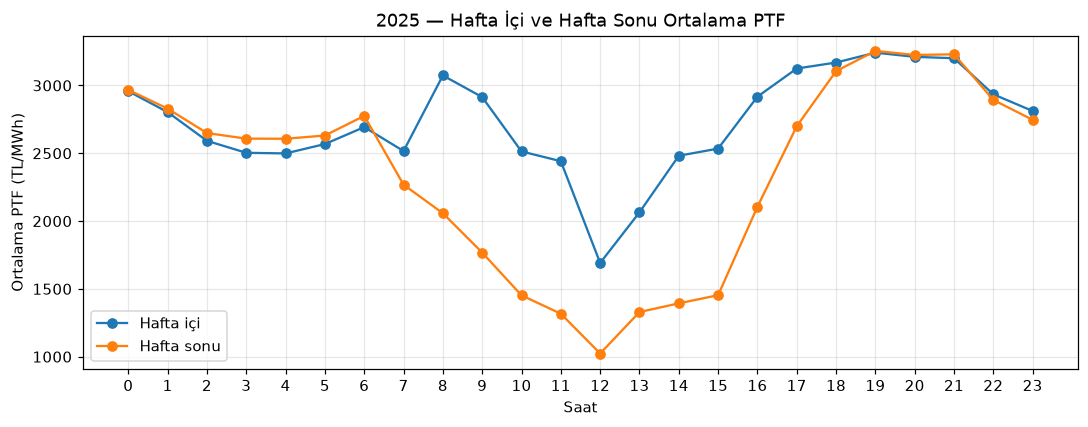

In [11]:
hafta_ici_sonu_2025.plot(figsize=(10, 4), marker="o")

plt.xticks(range(24))
plt.title("2025 — Hafta İçi ve Hafta Sonu Ortalama PTF")
plt.xlabel("Saat")
plt.ylabel("Ortalama PTF (TL/MWh)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

2025'te hafta sonu gündüz ortalamaları hafta içinden daha düşük; akşam saatlerinde fark daralıyor. Bu ilişki, fiyat farkının nedenini tek başına açıklamaz.


### 4.4. Yılları karşılaştırmak için ortak dönem seçimi

2026 verisi 6 Kasım'da sona eriyor. Yılları aynı aylar üzerinden
karşılaştırmak için üç yılda da tam bulunan ocak–ekim dönemi seçildi.
Kasım ve aralık kayıtları ana tablodan silinmedi; yalnızca bu
karşılaştırmanın dışında bırakıldı.

In [12]:
ortak_donem = df[df["ay"] <= 10]

yillik_ozet = ortak_donem.groupby("yil")["PTF (TL/MWh)"].agg(
    ["count", "mean", "median", "min", "max"]
)

yillik_ozet.round(2)

Out[12]: 
      count     mean   median  min     max
yil                                       
2024   7320  2191.72  2350.01  0.0  3000.0
2025   7296  2567.58  2842.99  0.0  3400.0
2026   7296  2066.15  2231.90  0.0  4500.0


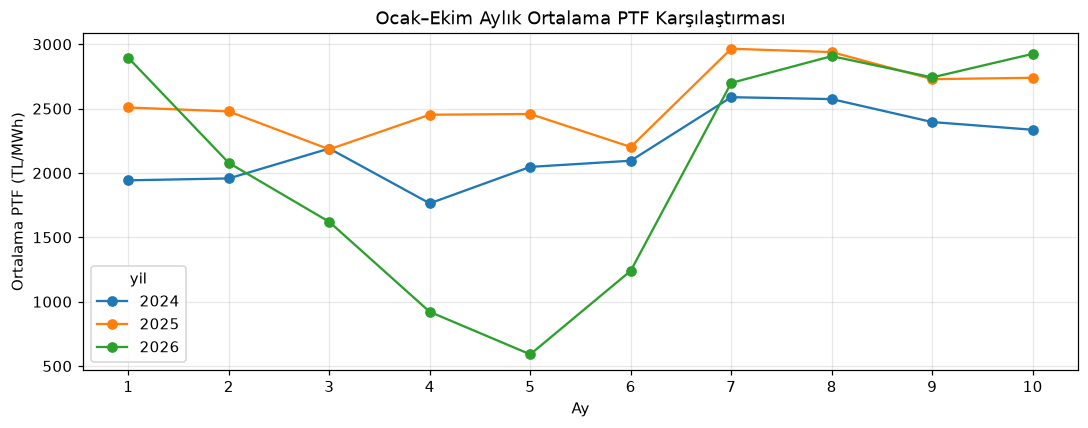

In [13]:
aylik_karsilastirma = ortak_donem.groupby(
    ["ay", "yil"]
)["PTF (TL/MWh)"].mean().unstack()

aylik_karsilastirma.plot(figsize=(10, 4), marker="o")

plt.xticks(range(1, 11))
plt.title("Ocak–Ekim Aylık Ortalama PTF Karşılaştırması")
plt.xlabel("Ay")
plt.ylabel("Ortalama PTF (TL/MWh)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

2024 artık yıl olduğundan ortak dönemde bir gün fazla içerir. Bu karşılaştırma aynı ayları kapsar; takvim ve gün türü bileşimini tamamen eşitlemez.


## 5. Fiyat dağılımları — Ortak dönem

Histogramlar aynı 150 TL/MWh genişliğindeki fiyat aralıklarını kullanır. Her çubuk o aralıktaki saat sayısını gösterir. Dikey eksenler bağımsız ölçeklenir; yükseklikler eksen değerleriyle birlikte okunmalıdır.


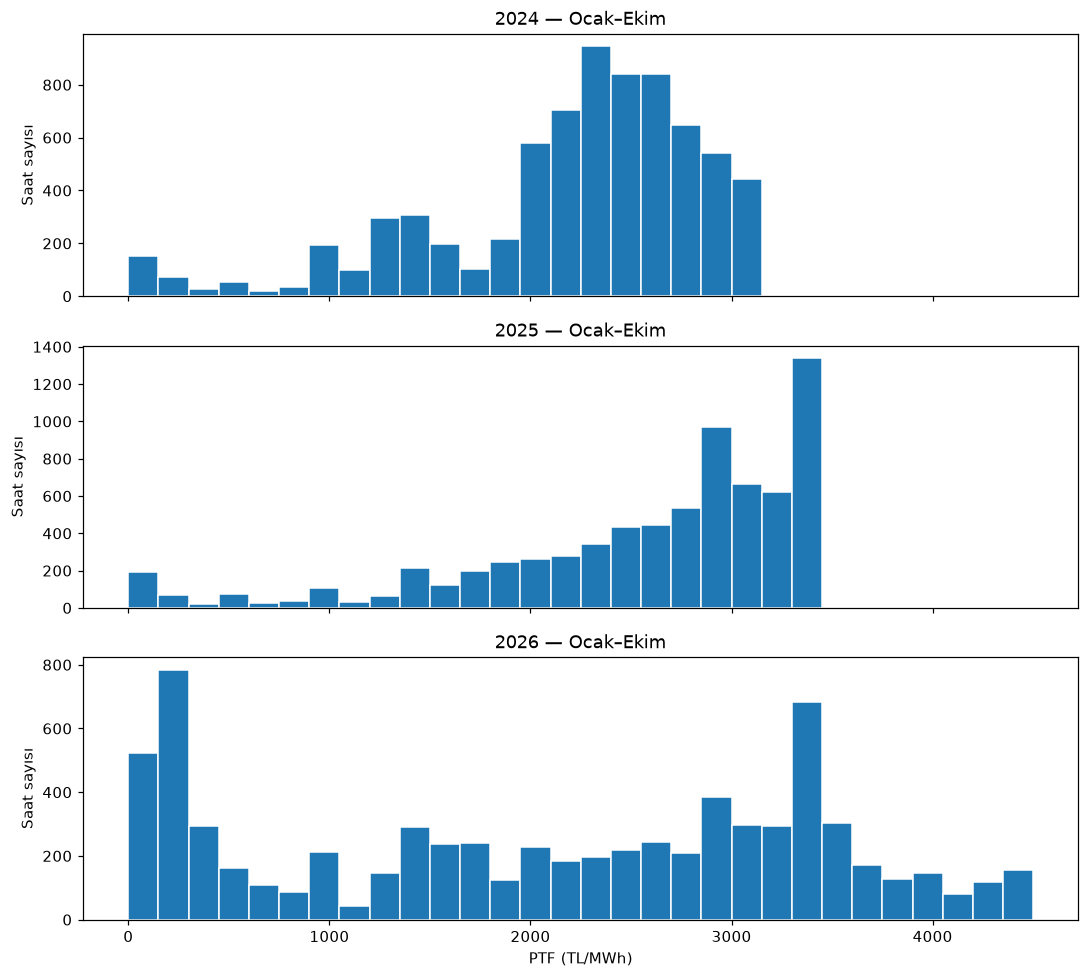

In [14]:
fig, eksenler = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

for eksen, yil in zip(eksenler, [2024, 2025, 2026]):
    fiyatlar = ortak_donem.loc[
        ortak_donem["yil"] == yil, "PTF (TL/MWh)"
    ]

    eksen.hist(fiyatlar, bins=30, range=(0, 4500), edgecolor="white")
    eksen.set_title(f"{yil} — Ocak–Ekim")
    eksen.set_ylabel("Saat sayısı")

eksenler[-1].set_xlabel("PTF (TL/MWh)")
plt.tight_layout()
plt.show()

### 5.1. 2026 ilkbaharının ayrıntısı

Histogramda 2026'nın hem düşük hem yüksek fiyatlarda yoğunlaştığı görülüyor. Aylık ortalama ve medyanı birlikte inceleyerek düşük fiyatların yaygınlığını değerlendiriyoruz. Kasım yalnızca ilk altı günü kapsar.


In [15]:
aylik_ozet_2026 = df_2026.groupby(
    df_2026["tarih_saat"].dt.month
)["PTF (TL/MWh)"].agg(["count", "mean", "median", "min", "max"])

aylik_ozet_2026.round(2)

Out[15]: 
            count     mean   median     min     max
tarih_saat                                         
1             744  2894.92  3057.00  715.11  3400.0
2             672  2078.20  2047.48    0.00  3400.0
3             744  1620.32  1620.00    0.00  3400.0
4             720   921.06   363.00    0.00  4500.0
5             744   590.90   189.99    0.00  4500.0
6             720  1240.16   800.00    0.00  4500.0
7             744  2699.61  2999.24  169.98  4500.0
8             744  2907.81  3157.78  175.00  4500.0
9             720  2742.43  2913.50    0.00  4500.0
10            744  2925.47  3023.60    0.00  4500.0
11            144  3139.84  3144.00  324.99  4500.0


In [16]:
sifir_orani_2026 = (
    df_2026["PTF (TL/MWh)"].eq(0)
    .groupby(df_2026["tarih_saat"].dt.month)
    .mean()
    .mul(100)
)

sifir_orani_2026.round(2)

Out[16]: 
tarih_saat
1      0.00
2      2.98
3      2.96
4     13.19
5     28.76
6      5.56
7      0.00
8      0.00
9      0.56
10     2.42
11     0.00
Name: PTF (TL/MWh), dtype: float64


## 2026 ilkbaharındaki düşük fiyatlar

- Nisanda ortalama PTF 921,06; medyan 363,00 TL/MWh.
- Mayısta ortalama PTF 590,90; medyan 189,99 TL/MWh.
- Sıfır fiyatlı saatlerin oranı nisanda %13,19, mayısta %28,76.
- Düşük medyanlar, düşük fiyatların yalnızca birkaç saatle sınırlı olmadığını gösteriyor.
- Bu değişimin nedenleri henüz doğrulanmadı.

## 6. Gün içi farklar ve uç değerler

### 6.1. Günlük en yüksek ve en düşük fiyat farkı

Bu fark fiyat esnekliğini gösteren bir ölçüdür; gerçekleştirilebilir tasarruf değildir. İşin süresi, izin verilen saatler ve ek giderler henüz hesaba katılmaz.


In [17]:
gunluk_fiyatlar = df.groupby(
    df["tarih_saat"].dt.date
)["PTF (TL/MWh)"].agg(["min", "max", "mean"])

gunluk_fiyatlar["fiyat_farki"] = (
    gunluk_fiyatlar["max"] - gunluk_fiyatlar["min"]
)

gunluk_fiyatlar.head()

Out[17]: 
                min      max         mean  fiyat_farki
tarih_saat                                            
2024-01-01   913.64  2601.44  1465.297083      1687.80
2024-01-02  1285.81  2700.00  2060.299583      1414.19
2024-01-03  1349.99  2690.02  2146.350417      1340.03
2024-01-04  1184.35  2689.01  2085.442083      1504.66
2024-01-05  1349.99  2700.00  2319.892083      1350.01


In [18]:
gunluk_fiyatlar.index = pd.to_datetime(gunluk_fiyatlar.index)

ortak_gunler = gunluk_fiyatlar[
    gunluk_fiyatlar.index.month <= 10
]

gunluk_fark_ozeti = ortak_gunler.groupby(
    ortak_gunler.index.year
)["fiyat_farki"].agg(["count", "mean", "median", "min", "max"])

gunluk_fark_ozeti.round(2)

Out[18]: 
            count     mean   median     min      max
tarih_saat                                          
2024          305  1576.46  1499.99  225.85  2800.01
2025          304  1955.41  1861.57  149.99  3400.00
2026          304  2866.84  2900.02  199.00  4500.00


Ocak–ekim günlük fark medyanları 2024'te 1.499,99, 2025'te 1.861,57 ve 2026'da 2.900,02 TL/MWh. İncelenen dönemde gün içi farklar yükseliyor.


### 6.2. IQR ile inceleme örneği — 2025 ocak–ekim

IQR, istatistiksel olarak alışılmadık kayıtları işaretlemek için kullanılır; bir hata tespit kuralı değildir. Yöntem yalnızca 2025 ortak dönemi üzerinde gösterilir. Alt ve üst sınırlar bütün ocak–ekim döneminden hesaplanır, her ay için yeniden hesaplanmaz. Düşük fiyatlar projenin konusu olduğu için işaretlenen kayıtlar korunur.


In [19]:
fiyatlar_2025 = ortak_donem.loc[
    ortak_donem["yil"] == 2025, "PTF (TL/MWh)"
]

q1 = fiyatlar_2025.quantile(0.25)
q3 = fiyatlar_2025.quantile(0.75)
iqr = q3 - q1

alt_sinir = q1 - 1.5 * iqr
ust_sinir = q3 + 1.5 * iqr

print("Alt sınır:", round(alt_sinir, 2))
print("Üst sınır:", round(ust_sinir, 2))

Alt sınır: 727.51
Üst sınır: 4651.51


In [20]:
uc_degerler_2025 = fiyatlar_2025[
    (fiyatlar_2025 < alt_sinir)
    | (fiyatlar_2025 > ust_sinir)
]

print("İşaretlenen saat sayısı:", len(uc_degerler_2025))
print(
    "İşaretlenen saatlerin oranı (%):",
    round(len(uc_degerler_2025) / len(fiyatlar_2025) * 100, 2)
)

İşaretlenen saat sayısı: 376
İşaretlenen saatlerin oranı (%): 5.15


In [21]:
uc_saatler_2025 = ortak_donem.loc[uc_degerler_2025.index]

aylik_uc_sayisi = uc_saatler_2025.groupby("ay").size()

aylik_toplam_saat = ortak_donem.loc[
    ortak_donem["yil"] == 2025
].groupby("ay").size()

aylik_uc_orani = (
    aylik_uc_sayisi.reindex(aylik_toplam_saat.index, fill_value=0)
    / aylik_toplam_saat
    * 100
)

aylik_uc_orani.round(2)

Out[21]: 
ay
1      0.13
2      0.00
3      7.39
4      7.78
5      9.68
6     14.17
7      1.48
8      1.08
9      5.56
10     4.17
dtype: float64


727,51–4.651,51 TL/MWh sınırlarının dışında 376 saat (%5,15) bulunuyor; tamamı alt sınırın altında. Aylık oran en yüksek haziranda (%14,17), ardından mayısta (%9,68). Bu inceleme tüm yılları kapsayan bir uç değer analizi değildir.


## 7. Zamansal ilişki ve saatlik değişim

### 7.1. Önceki gün ve önceki haftanın aynı saati

Saat dizisi sıralı ve kesintisiz olduğu için 24 ve 168 satırlık gecikmeler sırasıyla bir gün ve bir haftaya karşılık gelir. Bu bölüm ilişkiyi inceler; tahmin modeli veya doğruluk testi değildir.


In [22]:
# Saat dizisi kesintisiz olduğu için 24 satır, bir güne karşılık gelir.
gecikme_incelemesi = df[
    ["tarih_saat", "PTF (TL/MWh)"]
].copy()

gecikme_incelemesi["onceki_gun"] = (
    gecikme_incelemesi["PTF (TL/MWh)"].shift(24)
)

gecikme_incelemesi["onceki_hafta"] = (
    gecikme_incelemesi["PTF (TL/MWh)"].shift(168)
)

gecikme_incelemesi.iloc[168:173]

Out[22]: 
             tarih_saat  PTF (TL/MWh)  onceki_gun  onceki_hafta
168 2024-01-08 00:00:00        275.00     1349.98       1299.98
169 2024-01-08 01:00:00        129.99     1199.99       1299.98
170 2024-01-08 02:00:00        115.01     1144.63       1248.54
171 2024-01-08 03:00:00        110.86      500.00       1299.98
172 2024-01-08 04:00:00        110.86      447.07       1200.00


In [23]:
# Üç fiyatın da bulunduğu ortak satırlarda ilişkiyi hesaplıyoruz.
karsilastirma = gecikme_incelemesi.dropna()

karsilastirma[
    ["PTF (TL/MWh)", "onceki_gun", "onceki_hafta"]
].corr().round(3)

Out[23]: 
              PTF (TL/MWh)  onceki_gun  onceki_hafta
PTF (TL/MWh)          1.00       0.750         0.730
onceki_gun            0.75       1.000         0.641
onceki_hafta          0.73       0.641         1.000


In [24]:
for yil in [2024, 2025, 2026]:
    # Yılın ilk haftasını çıkararak gecikmelerin aynı yılda kalmasını sağlıyoruz.
    yil_verisi = karsilastirma[
        (karsilastirma["tarih_saat"].dt.year == yil)
        & (karsilastirma["tarih_saat"] >= f"{yil}-01-08")
    ]

    iliskiler = yil_verisi[
        ["PTF (TL/MWh)", "onceki_gun", "onceki_hafta"]
    ].corr()

    print(
        yil,
        "Önceki gün:", round(iliskiler.loc["PTF (TL/MWh)", "onceki_gun"], 3),
        "Önceki hafta:", round(iliskiler.loc["PTF (TL/MWh)", "onceki_hafta"], 3)
    )

2024 Önceki gün: 0.617 Önceki hafta: 0.635
2025 Önceki gün: 0.65 Önceki hafta: 0.681
2026 Önceki gün: 0.806 Önceki hafta: 0.752


### Önceki gün ve önceki haftayla fiyat ilişkisi

- Her yıl ayrı incelendiğinde, fiyatların önceki gün ve önceki haftanın
  aynı saatiyle pozitif ilişkili olduğu görüldü.
- Önceki gün / önceki hafta korelasyonları:
  - 2024: 0,617 / 0,635
  - 2025: 0,650 / 0,681
  - 2026: 0,806 / 0,752
- Her yılın ilk haftası, karşılaştırılan fiyatların aynı yılda kalması
  için bu hesaptan çıkarıldı.
- 2026 verisi 6 Kasım'a kadar olan dönemi kapsıyor.
- Korelasyon, tahmin doğruluğu değildir. Önceki gün ve önceki hafta
  fiyatları, tahmin aşamasında basit karşılaştırma yöntemleri olarak sınanacak.

### 7.2. Ardışık saatler arasındaki değişim

İşaretli fark yükseliş ve düşüşü, mutlak fark değişimin büyüklüğünü gösterir. Yıl karşılaştırması ocak–ekimle sınırlıdır; yıl geçişindeki tek saat dışarıda bırakılır.


In [25]:
saatlik_degisim = df[["tarih_saat", "PTF (TL/MWh)"]].copy()

# Saatler kesintisiz ve sıralı: her fiyatı bir önceki saatten çıkarıyoruz.
saatlik_degisim["degisim"] = saatlik_degisim["PTF (TL/MWh)"].diff()

saatlik_degisim["mutlak_degisim"] = (
    saatlik_degisim["degisim"].abs()
)

saatlik_degisim.head()

Out[25]: 
           tarih_saat  PTF (TL/MWh)  degisim  mutlak_degisim
0 2024-01-01 00:00:00       1299.98      NaN             NaN
1 2024-01-01 01:00:00       1299.98     0.00            0.00
2 2024-01-01 02:00:00       1248.54   -51.44           51.44
3 2024-01-01 03:00:00       1299.98    51.44           51.44
4 2024-01-01 04:00:00       1200.00   -99.98           99.98


In [26]:
# Ocak–ekim dönemini seç; yıl geçişlerini dışarıda bırak.
degisim_karsilastirma = saatlik_degisim[
    (saatlik_degisim["tarih_saat"].dt.month <= 10)
    & ~(
        (saatlik_degisim["tarih_saat"].dt.month == 1)
        & (saatlik_degisim["tarih_saat"].dt.day == 1)
        & (saatlik_degisim["tarih_saat"].dt.hour == 0)
    )
]

degisim_karsilastirma.groupby(
    degisim_karsilastirma["tarih_saat"].dt.year
)["mutlak_degisim"].agg(["mean", "median", "max"]).round(2)

Out[26]: 
              mean  median      max
tarih_saat                         
2024        231.93  146.36  1750.02
2025        284.11  160.19  2837.97
2026        379.76  220.04  3410.00


In [27]:
degisim_karsilastirma.nlargest(
    10, "mutlak_degisim"
)[["tarih_saat", "PTF (TL/MWh)", "degisim", "mutlak_degisim"]]

Out[27]: 
               tarih_saat  PTF (TL/MWh)  degisim  mutlak_degisim
20395 2026-04-29 19:00:00       4300.01  3410.00         3410.00
20731 2026-05-13 19:00:00       4100.00  3370.00         3370.00
20299 2026-04-25 19:00:00       4444.08  3244.07         3244.07
21164 2026-05-31 20:00:00       4300.00  3025.01         3025.01
20203 2026-04-21 19:00:00       4500.00  3000.02         3000.02
20587 2026-05-07 19:00:00       3799.99  2999.99         2999.99
19987 2026-04-12 19:00:00       3451.53  2901.53         2901.53
18656 2026-02-16 08:00:00       3129.99  2857.99         2857.99
19928 2026-04-10 08:00:00       3599.99  2849.98         2849.98
15952 2025-10-26 16:00:00       3233.07  2837.97         2837.97


In [28]:
saatlik_degisim.loc[
    (saatlik_degisim["tarih_saat"] >= "2026-04-29 16:00")
    & (saatlik_degisim["tarih_saat"] < "2026-04-29 22:00")
]

Out[28]: 
               tarih_saat  PTF (TL/MWh)  degisim  mutlak_degisim
20392 2026-04-29 16:00:00        169.91   169.91          169.91
20393 2026-04-29 17:00:00        398.01   228.10          228.10
20394 2026-04-29 18:00:00        890.01   492.00          492.00
20395 2026-04-29 19:00:00       4300.01  3410.00         3410.00
20396 2026-04-29 20:00:00       4500.00   199.99          199.99
20397 2026-04-29 21:00:00       4399.99  -100.01          100.01


Ocak–ekim mutlak saatlik değişim ortalamaları 2024'te 231,93, 2025'te 284,11 ve 2026'da 379,76 TL/MWh. Medyanlar da yükseliyor. Seçilen en büyük 10 değişimin tamamı yükseliş; 9'u 2026'da. Bu, tüm değişimlerin yükseliş olduğu anlamına gelmez.


## 8. Kaynak doğrulaması

9 Kasım 2026'da EPİAŞ PTF ekranındaki iki örnek gün notebook sonuçlarıyla karşılaştırıldı:

| Tarih | Kontrol edilen kayıtlar | Sonuç |
|---|---|---|
| 29 Nisan 2026 | Seçilen akşam fiyatları ve sıfır fiyatlı saatler | Eşleşti |
| 1 Mayıs 2026 | Günün 24 saatlik fiyatları | Eşleşti |

29 Nisan'da 18.00, 19.00 ve 20.00 fiyatları sırasıyla 890,01; 4.300,01; 4.500,00 TL/MWh. 1 Mayıs'ta 06.00–17.00 aralığındaki 11 saat sıfır PTF içeriyor. Seçilen kayıtlarda farklılık bulunmadı. Bu kontroller bütün veri setini veya fiyat değişimlerinin nedenlerini doğrulamaz.


## 9. Sonuç ve kapsam

- 1 Ocak 2024–6 Kasım 2026 arasında 24.984 saatlik kayıt var. Beklenen saatler tam; tekrar veya eksik fiyat bulunmadı.
- Fiyatlar saat, ay ve gün türüne göre farklılaşıyor. Sabit bir “her zaman ucuz saat” kuralı için bu ortalamalar yeterli değil.
- Ortak ocak–ekim döneminde günlük farklar ve mutlak saatlik değişimler yıllara göre yükseldi.
- Önceki gün ve haftayla pozitif ilişki var; hangi yöntemin daha iyi tahmin vereceği ayrı bir test gerektiriyor.
- Sıfır ve istatistiksel uç değerler silinmedi. Seçilen iki gün için kaynak kontrolü yapıldı.

### Analizin sınırları

Fiyatlar nominal TL cinsindedir. PTF nihai elektrik faturası değildir. Bu çalışma talep, üretim ve hava durumu gibi dış değişkenleri incelemediğinden fiyat hareketlerine nedensel açıklama getirmez. İncelenen dönemler gelecekteki fiyat düzenini garanti etmez.

Bu notebook sonraki modellemeye yön veren keşifsel bir çalışmadır. 2026 verileri de incelendiği için bu dönem ileride tamamen görülmemiş bir test kümesi olarak sunulmamalıdır. Tahmin değerlendirmesinde zaman sırası korunmalı ve değerlendirme tasarımı ayrıca belirtilmelidir.

Henüz gerçek fabrika kısıtları, uygulanabilir çizelge veya net tasarruf doğrulanmadı.
